In [1]:
%pip -q install "streamlit>=1.38,<2" "yfinance>=0.2.50,<2" "plotly>=5.24,<7" "pandas>=2.1,<3" "numpy>=1.26,<3" pillow requests

In [2]:
import sys, streamlit, pandas, numpy, plotly, yfinance
print("Python:", sys.version.split()[0])
print("Streamlit:", streamlit.__version__)
print("Pandas:", pandas.__version__)
print("Plotly:", plotly.__version__)
print("yfinance:", yfinance.__version__)

Python: 3.13.18
Streamlit: 1.67.0
Pandas: 2.2.3
Plotly: 5.24.1
yfinance: 0.2.66


In [3]:
#Aquí creo la primera página de KAPITAL:

%%writefile app.py
import streamlit as st

st.set_page_config(
    page_title="KAPITAL",
    page_icon="📈",
    layout="wide"
)

st.title("📈 KAPITAL")

st.subheader("Análisis financiero del sector de semiconductores")

st.write(
    "Aplicación interactiva para analizar y comparar "
    "la rentabilidad y el riesgo de NVIDIA, AMD y Qualcomm "
    "durante el período 2021-2025."
)

st.info(
    "KAPITAL utiliza datos históricos reales de Yahoo Finance "
    "para evaluar el comportamiento de las acciones mediante "
    "indicadores financieros de rentabilidad y riesgo."
)



Writing app.py


In [4]:
#Guardar la primera version

from pathlib import Path
from datetime import datetime
Path("versiones").mkdir(exist_ok=True)
Path("versiones/01_primera_app.py").write_text(Path("app.py").read_text(encoding="utf-8"), encoding="utf-8")
print("Versión 01 guardada")

Versión 01 guardada


In [5]:
#para iniciar la aplicación Streamlit:

import subprocess, time, requests
from pathlib import Path

# Evitar servidores anteriores
subprocess.run(["pkill", "-f", "[s]treamlit run app.py"], check=False)

log_streamlit = open("/tmp/kapital_streamlit.log", "w")

servidor = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.fileWatcherType=poll"
    ],
    stdout=log_streamlit,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

for intento in range(20):
    try:
        respuesta = requests.get(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=2
        )
        if respuesta.status_code == 200:
            print("✅ KAPITAL funcionando:", respuesta.status_code)
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    print("❌ No responde Streamlit. Últimos mensajes:")
    print(
        Path("/tmp/kapital_streamlit.log")
        .read_text(errors="replace")[-3000:]
    )

✅ KAPITAL funcionando: 200


In [6]:
#Preparar Cloudflared
import platform, urllib.request, os
from pathlib import Path

arquitectura = platform.machine().lower()

archivo = {
    "x86_64": "cloudflared-linux-amd64",
    "aarch64": "cloudflared-linux-arm64"
}.get(arquitectura)

if not archivo:
    raise RuntimeError(f"Arquitectura no contemplada: {arquitectura}")

url = f"https://github.com/cloudflare/cloudflared/releases/latest/download/{archivo}"

if not Path("/tmp/cloudflared").exists():
    urllib.request.urlretrieve(url, "/tmp/cloudflared")

os.chmod("/tmp/cloudflared", 0o755)

print("Cloudflared preparado para", arquitectura)

Cloudflared preparado para x86_64


In [7]:
#Crear Enlace Publico

import re, subprocess, time
from pathlib import Path

subprocess.run(["pkill", "-f", "[c]loudflared tunnel --url"], check=False)

registro = open("/tmp/kapital_cloudflare.log", "w")

tunel = subprocess.Popen(
    [
        "/tmp/cloudflared", "tunnel",
        "--url", "http://127.0.0.1:8501",
        "--no-autoupdate"
    ],
    stdout=registro,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

url_publica = None

for intento in range(25):
    time.sleep(1)
    texto = Path("/tmp/kapital_cloudflare.log").read_text(errors="replace")

    encontrado = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        texto
    )

    if encontrado:
        url_publica = encontrado.group(0)
        break

if url_publica:
    print("🌐 ABRE KAPITAL EN UNA PESTAÑA NUEVA:", url_publica)
else:
    print("No se obtuvo URL. Diagnóstico:")
    print(texto[-2500:])


🌐 ABRE KAPITAL EN UNA PESTAÑA NUEVA: https://brilliant-glance-believes-broadband.trycloudflare.com


In [9]:
#Verificar funcionamiento

from pathlib import Path
import requests

try:
    r = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=5
    )
    print("Servidor local:", r.status_code, r.text)
except Exception as e:
    print("Servidor local sin respuesta:", e)

print(
    "\nRegistro Streamlit:\n",
    Path("/tmp/kapital_streamlit.log").read_text(errors="replace")[-900:]
)

print(
    "\nRegistro Cloudflare:\n",
    Path("/tmp/kapital_cloudflare.log").read_text(errors="replace")[-900:]
)


Servidor local: 200 ok

Registro Streamlit:
 

2026-11-10 23:11:08.781 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.74.134.170:8501



Registro Cloudflare:
 t=region1.v2.argotunnel.com
2026-11-10T23:11:30Z INF precheck component="UDP Connectivity" details="QUIC connection successful" run_id=cc6f39e5-2e84-4b23-98c0-6f50ab93bdfa status=pass target=region2.v2.argotunnel.com
2026-11-10T23:11:30Z INF precheck component="TCP Connectivity" details="HTTP/2 connection successful" run_id=cc6f39e5-2e84-4b23-98c0-6f50ab93bdfa status=pass target=region1.v2.argotunnel.com
2026-11-10T23:11:30Z INF precheck component="TCP Connectivity" details="HTTP/2 connection successful" run_id=cc6f39e5-2e84-4b23-98c0-6f50ab93bdfa status=pass target=region2.v2.argotunnel.com
2026-11-10T23:11:30Z INF precheck component="Cloudflare API" details="API is reachable" run_i

In [10]:
#Diseño principal de KAPITAL

%%writefile app.py
import streamlit as st

st.set_page_config(
    page_title="KAPITAL | Análisis financiero",
    page_icon="📈",
    layout="wide"
)

# Estilo visual
# Estilo visual
st.markdown("""
<style>
    .stApp {
        background-color: #F5F7F8;
        color: #263746;
    }

    [data-testid="stSidebar"] {
        background-color: #E8EFF1;
    }

    .main-title {
        font-size: 48px;
        font-weight: 800;
        color: #173B45;
        letter-spacing: 3px;
    }

    .subtitle {
        color: #526B73;
        font-size: 17px;
    }

    .section-title {
        color: #087E83;
        font-size: 23px;
        font-weight: 700;
    }

    .info-card {
        background: #FFFFFF;
        padding: 22px;
        border-radius: 12px;
        border: 1px solid #D8E3E5;
        margin-bottom: 12px;
    }

    .info-card h4 {
        color: #087E83;
        margin-bottom: 8px;
    }

    .info-card p {
        color: #344B54;
    }

    [data-testid="stMetricValue"] {
        color: #173B45;
    }

    [data-testid="stMetricLabel"] {
        color: #526B73;
    }
</style>
""", unsafe_allow_html=True)

# Banner principal
from pathlib import Path

if Path("assets/portada_kapital.png").exists():
    st.image("assets/portada_kapital.png", use_container_width=True)

# Portada
st.markdown('<div class="main-title">KAPITAL<span style="color:#38bdf8;">.</span></div>',
            unsafe_allow_html=True)

st.markdown(
    '<div class="subtitle">INTELIGENCIA FINANCIERA · SECTOR SEMICONDUCTORES</div>',
    unsafe_allow_html=True
)

st.write("")
st.markdown("""
<div class="info-card">
    <h4>Analiza. Compara. Comprende.</h4>
    <p>
    Explora el comportamiento histórico de NVIDIA, AMD y Qualcomm
    entre 2021 y 2025 para identificar cuál presentó el mejor
    equilibrio entre rentabilidad y riesgo.
    </p>
</div>
""", unsafe_allow_html=True)

# Menú lateral
st.sidebar.markdown("## KAPITAL")
st.sidebar.caption("Panel de análisis financiero")

activos = st.sidebar.multiselect(
    "Empresas para analizar",
    ["NVIDIA (NVDA)", "AMD (AMD)", "Qualcomm (QCOM)"],
    default=["NVIDIA (NVDA)", "AMD (AMD)", "Qualcomm (QCOM)"]
)

st.sidebar.markdown("---")
st.sidebar.write("**Período de estudio**")
st.sidebar.info("Enero 2021 – Diciembre 2025")

# Indicadores principales
st.markdown('<div class="section-title">Indicadores financieros</div>',
            unsafe_allow_html=True)

col1, col2, col3, col4 = st.columns(4)

col1.metric("Rentabilidad acumulada", "Pendiente")
col2.metric("Volatilidad anualizada", "Pendiente")
col3.metric("Máximo drawdown", "Pendiente")
col4.metric("Ratio de Sharpe", "Pendiente")

st.caption("Los indicadores se calcularán con datos históricos reales de Yahoo Finance.")

# Secciones
p1, p2, p3, p4 = st.tabs([
    "🌐 Panorama general",
    "📈 Rentabilidad",
    "⚠️ Riesgo",
    "📚 Metodología"
])

with p1:
    st.subheader("Panorama del sector")
    st.write(
        "Comparación histórica de tres empresas relevantes "
        "del sector de semiconductores."
    )
    st.info("Aquí mostraremos la evolución de los precios de las tres acciones.")

with p2:
    st.subheader("Análisis de rentabilidad")
    st.write(
        "Evaluaremos el crecimiento de cada acción mediante "
        "la rentabilidad acumulada."
    )
    st.info("Aquí se incluirán los gráficos comparativos de rentabilidad.")

with p3:
    st.subheader("Análisis de riesgo")
    st.write(
        "Estudiaremos las fluctuaciones y las caídas más importantes "
        "de cada acción."
    )
    st.info(
        "Aquí se mostrarán la volatilidad anualizada, el máximo drawdown "
        "y el ratio de Sharpe."
    )

with p4:
    st.subheader("¿Cómo se realiza el análisis?")
    st.write("Los datos se obtendrán de Yahoo Finance mediante Python.")

    st.markdown("""
    **Indicadores utilizados:**

    - Rentabilidad acumulada.
    - Volatilidad anualizada.
    - Máximo drawdown.
    - Ratio de Sharpe.

    **Período:** 2021–2025.

    **Fuente de datos:** Yahoo Finance.
    """)

st.markdown("---")
st.caption("KAPITAL | Proyecto de analítica financiera · ITM")

Overwriting app.py


In [11]:
from pathlib import Path

Path("versiones/02_layout.py").write_text(
    Path("app.py").read_text(encoding="utf-8"),
    encoding="utf-8"
)

print("Versión 02 de KAPITAL guardada correctamente.")


Versión 02 de KAPITAL guardada correctamente.


Portada gráfica de KAPITAL creada correctamente.


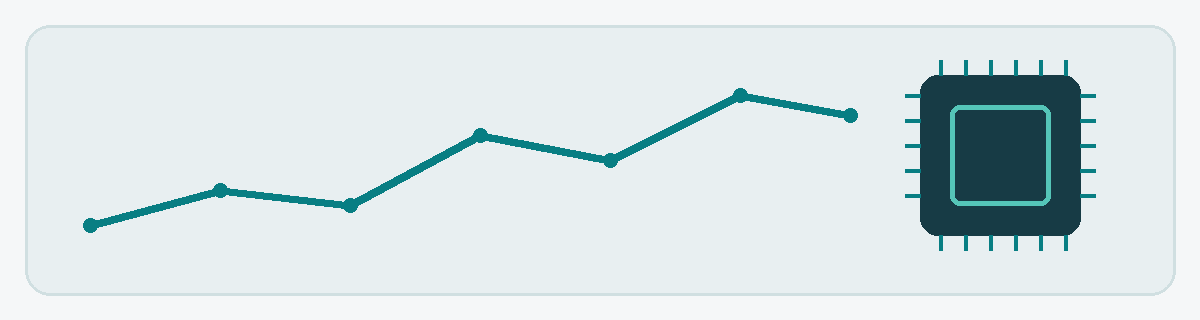

In [12]:
#portada gráfica de KAPITAL.
from PIL import Image, ImageDraw
from pathlib import Path

# Crear carpeta
Path("assets").mkdir(exist_ok=True)

# Crear banner
imagen = Image.new("RGB", (1200, 320), "#F5F7F8")
d = ImageDraw.Draw(imagen)

# Panel decorativo
d.rounded_rectangle(
    (25, 25, 1175, 295),
    radius=25,
    fill="#E8EFF1",
    outline="#D0DFE1",
    width=3
)

# Gráfica financiera
puntos = [
    (90, 225), (220, 190), (350, 205),
    (480, 135), (610, 160), (740, 95),
    (850, 115)
]

d.line(puntos, fill="#087E83", width=8, joint="curve")

# Puntos de la gráfica
for x, y in puntos:
    d.ellipse((x-7, y-7, x+7, y+7), fill="#087E83")

# Microchip decorativo
d.rounded_rectangle(
    (920, 75, 1080, 235),
    radius=18,
    fill="#173B45"
)

d.rounded_rectangle(
    (950, 105, 1050, 205),
    radius=10,
    outline="#55C5B8",
    width=5
)

# Conexiones del microchip
for x in range(940, 1070, 25):
    d.line((x, 60, x, 75), fill="#087E83", width=4)
    d.line((x, 235, x, 250), fill="#087E83", width=4)

for y in range(95, 220, 25):
    d.line((905, y, 920, y), fill="#087E83", width=4)
    d.line((1080, y, 1095, y), fill="#087E83", width=4)

# Guardar imagen
imagen.save("assets/portada_kapital.png")

print("Portada gráfica de KAPITAL creada correctamente.")

display(imagen)


In [13]:
#Aplicación con datos reales

%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import yfinance as yf
from pathlib import Path

st.set_page_config(
    page_title="KAPITAL | Análisis financiero",
    page_icon="📈",
    layout="wide"
)

# Diseño visual
st.markdown("""
<style>
    .stApp {
        background-color: #F5F7F8;
        color: #263746;
    }
    [data-testid="stSidebar"] {
        background-color: #E8EFF1;
    }
    .main-title {
        font-size: 48px;
        font-weight: 800;
        color: #173B45;
        letter-spacing: 3px;
    }
    .subtitle {
        color: #526B73;
        font-size: 17px;
    }
    .section-title {
        color: #087E83;
        font-size: 23px;
        font-weight: 700;
    }
    .info-card {
        background: #FFFFFF;
        padding: 22px;
        border-radius: 12px;
        border: 1px solid #D8E3E5;
        margin-bottom: 12px;
    }
    .info-card h4 {
        color: #087E83;
    }
    .info-card p {
        color: #344B54;
    }
</style>
""", unsafe_allow_html=True)

# Banner y encabezado
if Path("assets/portada_kapital.png").exists():
    st.image("assets/portada_kapital.png", use_container_width=True)

st.markdown(
    '<div class="main-title">KAPITAL<span style="color:#38bdf8;">.</span></div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">INTELIGENCIA FINANCIERA · SECTOR SEMICONDUCTORES</div>',
    unsafe_allow_html=True
)

st.write("")

st.markdown("""
<div class="info-card">
    <h4>Analiza. Compara. Comprende.</h4>
    <p>
    Compara el comportamiento histórico de NVIDIA, AMD y Qualcomm
    entre 2021 y 2025 para identificar cuál presentó el mejor
    equilibrio entre rentabilidad y riesgo.
    </p>
</div>
""", unsafe_allow_html=True)

# Configuración lateral
st.sidebar.markdown("## KAPITAL")
st.sidebar.caption("Panel de análisis financiero")

tickers = {
    "NVIDIA (NVDA)": "NVDA",
    "AMD (AMD)": "AMD",
    "Qualcomm (QCOM)": "QCOM"
}

activos = st.sidebar.multiselect(
    "Empresas para analizar",
    list(tickers.keys()),
    default=list(tickers.keys())
)

tasa_libre_riesgo = st.sidebar.number_input(
    "Tasa libre de riesgo anual (%)",
    min_value=0.0,
    max_value=30.0,
    value=0.0,
    step=0.5
)

st.sidebar.markdown("---")
st.sidebar.write("**Período de estudio**")
st.sidebar.info("Enero 2021 – Diciembre 2025")

# Consulta de datos reales
@st.cache_data
def obtener_datos(simbolos):
    datos = yf.download(
        tickers=list(simbolos),
        start="2021-01-01",
        end="2026-01-01",
        auto_adjust=True,
        progress=False
    )

    if datos.empty:
        return pd.DataFrame()

    if isinstance(datos.columns, pd.MultiIndex):
        precios = datos["Close"]
    else:
        precios = datos[["Close"]]
        precios.columns = list(simbolos)

    if isinstance(precios, pd.Series):
        precios = precios.to_frame()

    return precios.dropna(how="all")


if not activos:
    st.warning("Selecciona al menos una empresa para comenzar el análisis.")
    st.stop()

simbolos = [tickers[activo] for activo in activos]

with st.spinner("Consultando datos históricos de Yahoo Finance..."):
    try:
        precios = obtener_datos(tuple(simbolos))
    except Exception as error:
        st.error(f"No fue posible obtener los datos: {error}")
        st.stop()

if precios.empty:
    st.error("No se encontraron datos históricos. Intenta nuevamente.")
    st.stop()

# Cálculo de rendimientos
rendimientos = precios.pct_change().dropna(how="all")

# Cálculo de indicadores
tasa_diaria = (1 + tasa_libre_riesgo / 100) ** (1 / 252) - 1

resultados = {}

for activo in precios.columns:
    serie = precios[activo].dropna()
    retorno = rendimientos[activo].dropna()

    if len(serie) < 2 or retorno.empty:
        continue

    rentabilidad = (serie.iloc[-1] / serie.iloc[0] - 1) * 100

    volatilidad = retorno.std() * np.sqrt(252) * 100

    maximos = serie.cummax()
    drawdown = serie / maximos - 1
    max_drawdown = drawdown.min() * 100

    desviacion = retorno.std()
    if desviacion > 0:
        sharpe = (
            (retorno.mean() - tasa_diaria)
            / desviacion
        ) * np.sqrt(252)
    else:
        sharpe = np.nan

    resultados[activo] = {
        "Rentabilidad acumulada (%)": rentabilidad,
        "Volatilidad anualizada (%)": volatilidad,
        "Máximo drawdown (%)": max_drawdown,
        "Ratio de Sharpe": sharpe
    }

metricas = pd.DataFrame(resultados).T

# Navegación
p1, p2, p3, p4 = st.tabs([
    "🌐 Panorama general",
    "📈 Rentabilidad",
    "⚠️ Riesgo",
    "📚 Metodología"
])

# Panorama general
with p1:
    st.subheader("Panorama del sector")

    st.write(
        "Comportamiento histórico de las empresas seleccionadas "
        "durante el período 2021–2025."
    )

    st.caption("Fuente: Yahoo Finance. Precios ajustados en USD.")

    precios_base = precios / precios.apply(
        lambda columna: columna.dropna().iloc[0]
    ) * 100

    st.markdown("**Evolución de las acciones (base 100)**")
    st.line_chart(precios_base)

    st.markdown("**Resumen de indicadores financieros**")
    st.dataframe(
        metricas.round(3),
        use_container_width=True
    )

# Rentabilidad
with p2:
    st.subheader("Análisis de rentabilidad")

    st.write(
        "Comparamos el crecimiento acumulado de las acciones "
        "durante los cinco años."
    )

    st.bar_chart(metricas[["Rentabilidad acumulada (%)"]])

    st.markdown("**Rentabilidad acumulada por empresa**")
    st.dataframe(
        metricas[["Rentabilidad acumulada (%)"]].round(2),
        use_container_width=True
    )

# Riesgo
with p3:
    st.subheader("Análisis de riesgo")

    st.write(
        "Evaluamos las fluctuaciones, las caídas y la rentabilidad "
        "obtenida en relación con el riesgo."
    )

    st.markdown("**Volatilidad anualizada**")
    st.bar_chart(metricas[["Volatilidad anualizada (%)"]])

    st.markdown("**Máximo drawdown**")
    st.bar_chart(metricas[["Máximo drawdown (%)"]])

    st.markdown("**Ratio de Sharpe**")
    st.bar_chart(metricas[["Ratio de Sharpe"]])

    st.markdown("**Evolución de las caídas desde máximos históricos**")

    maximos = precios.cummax()
    drawdowns = (precios / maximos - 1) * 100

    st.line_chart(drawdowns)

# Metodología
with p4:
    st.subheader("Metodología del análisis")

    st.markdown("""
    **Fuente de información:** Yahoo Finance.

    **Período:** 2021–2025.

    **Empresas analizadas:** NVIDIA, AMD y Qualcomm.

    **Indicadores financieros:**

    1. **Rentabilidad acumulada:** crecimiento porcentual entre
       el precio inicial y final.
    2. **Volatilidad anualizada:** desviación estándar de los
       rendimientos diarios multiplicada por √252.
    3. **Máximo drawdown:** mayor caída desde un máximo histórico.
    4. **Ratio de Sharpe:** rentabilidad excedente dividida
       por la volatilidad, anualizada.

    **Consideraciones:** se utilizan precios ajustados y 252
    jornadas bursátiles para la anualización. La tasa libre de
    riesgo inicial está configurada en 0%; puede modificarse
    desde el menú lateral.

    Los resultados históricos no garantizan resultados futuros.
    """)

st.markdown("---")
st.caption("KAPITAL | Proyecto de analítica financiera · ITM")


Overwriting app.py


In [14]:
from pathlib import Path

Path("versiones/03_datos_reales.py").write_text(
    Path("app.py").read_text(encoding="utf-8"),
    encoding="utf-8"
)

print("Versión 03 de KAPITAL guardada correctamente.")


Versión 03 de KAPITAL guardada correctamente.


In [15]:
#Revisar estructura de la aplicación
from pathlib import Path

codigo = Path("app.py").read_text(encoding="utf-8")
lineas = codigo.splitlines()

for i, linea in enumerate(lineas):
    if "with p1:" in linea:
        inicio = max(0, i - 2)
        fin = min(len(lineas), i + 25)

        print(
            "\n".join(
                f"{j+1}: {lineas[j]}"
                for j in range(inicio, fin)
            )
        )
        break


200: 
201: # Panorama general
202: with p1:
203:     st.subheader("Panorama del sector")
204: 
205:     st.write(
206:         "Comportamiento histórico de las empresas seleccionadas "
207:         "durante el período 2021–2025."
208:     )
209: 
210:     st.caption("Fuente: Yahoo Finance. Precios ajustados en USD.")
211: 
212:     precios_base = precios / precios.apply(
213:         lambda columna: columna.dropna().iloc[0]
214:     ) * 100
215: 
216:     st.markdown("**Evolución de las acciones (base 100)**")
217:     st.line_chart(precios_base)
218: 
219:     st.markdown("**Resumen de indicadores financieros**")
220:     st.dataframe(
221:         metricas.round(3),
222:         use_container_width=True
223:     )
224: 
225: # Rentabilidad
226: with p2:


In [16]:
import yfinance as yf

print("Versión de yfinance:", yf.__version__)

Versión de yfinance: 0.2.66


In [17]:
from pathlib import Path
Path("versiones/04_kapital_final.py").write_text(Path("app.py").read_text(encoding="utf-8"), encoding="utf-8")
print("Versión final guardada. Comprueba el navegador y modifica los tickers.")

Versión final guardada. Comprueba el navegador y modifica los tickers.
